# Step 3 – Exploratory Data Analysis

* The source code is in `src/` (`data_loading`, `cost_model`, `eda`, `plotting`).
* Paths and assumptions are in `configs/eda.yaml`. 
* Plots are written to `plots/` and tables to `report/tables/`.
* Summary of findings: `report/03_eda_report.md`.

In [1]:
import pandas as pd
import numpy as np
from IPython.display import display

from src.config import load_config
from src import data_loading as dl, cost_model as cm, eda, plotting as pl

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pl.set_style()

cfg = load_config("eda")
P = cfg["paths"]
PLOTS, TABLES = P["plots"], P["tables"]
TABLES.mkdir(parents=True, exist_ok=True)
H = cfg["horizons"]
REG = cfg["regimes"]

def save(df, name):
    df.to_csv(TABLES / f"{name}.csv")
    return df

## 0. Data inventory and quality checks
One monthly panel in EUR where a price exists (LME Cu/Al, Ni/Zn/iron ore converted with ECB EUR/USD, MEPS/CRU steel,
epoxy) and indices for the PPIs. Dates snapped to month start. No imputation.

In [2]:
panel = dl.build_eur_panel(P)
display(save(dl.coverage_table(panel), "coverage"))

,label,first,last,n_obs,internal_gaps
series,,,,,
cu_eur,Copper LME (EUR/t),2016-01,2026-10,130,0
al_eur,Aluminium LME (EUR/t),2016-01,2026-10,130,0
ni_eur,Nickel LME (EUR/t),2016-11,2026-09,119,0
zn_eur,Zinc LME (EUR/t),2016-11,2026-09,119,0
iron_ore_eur,Iron ore 62% (EUR/t),2016-11,2026-09,119,0
eurusd,EUR/USD (USD per EUR),2016-11,2026-10,120,0
steel_cr_de,CR coil Germany MEPS (EUR/t),2012-11,2026-10,168,0
steel_cr_fr,CR coil France MEPS (EUR/t),2012-11,2026-10,168,0
steel_hdg_de,HDG coil Germany MEPS (EUR/t),2012-11,2026-10,168,0


In [3]:
# Cross-check: Westmetall LME cash (EUR) vs IMF-based D01/D02 from the challenge CSV
display(dl.lme_vs_imf_check(P))

,n_months,median_abs_diff_pct,max_abs_diff_pct
copper,119.0,0.123,0.788
aluminium,119.0,0.182,1.128


In [4]:
# Data-quality scan: isolated one-month spikes (typo-like) in the raw epoxy file and in the panel
raw_ep = dl.load_epoxy(P, mask_spikes=False)
print("Raw epoxy file:", {c: list(raw_ep.index[dl.isolated_spikes(raw_ep[c])].strftime("%Y-%m")) for c in raw_ep})
print("Panel after cleaning:", {c: list(panel.index[dl.isolated_spikes(panel[c])].strftime("%Y-%m"))
                                for c in panel if dl.isolated_spikes(panel[c]).any()})
display(raw_ep.loc["2026-03":"2026-07"].round(0))

Raw epoxy file: {'benzene': [], 'acetone': [], 'epichlorohydrin': ['2026-05'], 'epoxy_other_costs': [], 'epoxy': []}
Panel after cleaning: {'power_fr': ['2025-05']}


,benzene,acetone,epichlorohydrin,epoxy_other_costs,epoxy
month,,,,,
2026-03-01,919.0,985.0,2154.0,2414.0,4556.0
2026-04-01,1256.0,1442.0,2479.0,2419.0,4928.0
2026-05-01,1296.0,1554.0,257.0,2344.0,3593.0
2026-06-01,1423.0,1520.0,2607.0,2312.0,4983.0
2026-07-01,1303.0,1317.0,2503.0,2347.0,4877.0


In [5]:
# Teardown should-cost (EUR). Note the SGC column: total €19 is clearly a parsing/mass error in the source.
display(dl.load_teardown_costs(P))

,total,material,process,labour,overhead,insulation
Schneider,3008.865,2403.985,21.540,30.691,552.649,SF6
ormazabal,1692.365,1450.649,7.508,13.465,220.743,SF6
SGC – SwitchGear Company nv,19.352,11.537,2.155,3.135,2.524,SF6
ABB,3462.286,2842.083,6.469,12.842,600.893,SF6
Siemens,3307.334,2679.004,7.240,13.620,607.469,SF6
eaton,767.360,641.368,14.864,11.037,100.090,Air/vacuum


In [6]:
# The RMU price benchmark *is readable* in this copy (yearly P10/P50/P90 selling price per brand)
bench = dl.load_rmu_benchmark(P)
display(bench.pivot(index="Year", columns="Brand", values="p50"))

Brand,ABB,Eaton,Ormazabal,Schneider Electric,Siemens,SwitchGear Company
Year,,,,,,
2017,7181,9948,5709,7230,8450,5490
2018,7208,10092,5687,7295,8450,5513
2019,7308,9670,5758,7318,8484,5489
2020,7227,9810,5683,7261,8486,5475
2021,7744,10440,6316,7748,9203,5846
2022,8205,10634,6643,8311,9852,6216
2023,8747,10772,6944,8407,10302,6648
2024,8794,10772,7097,8727,10316,6800
2025,8782,10661,7107,8740,10318,6921


## 3.1 Univariate analysis

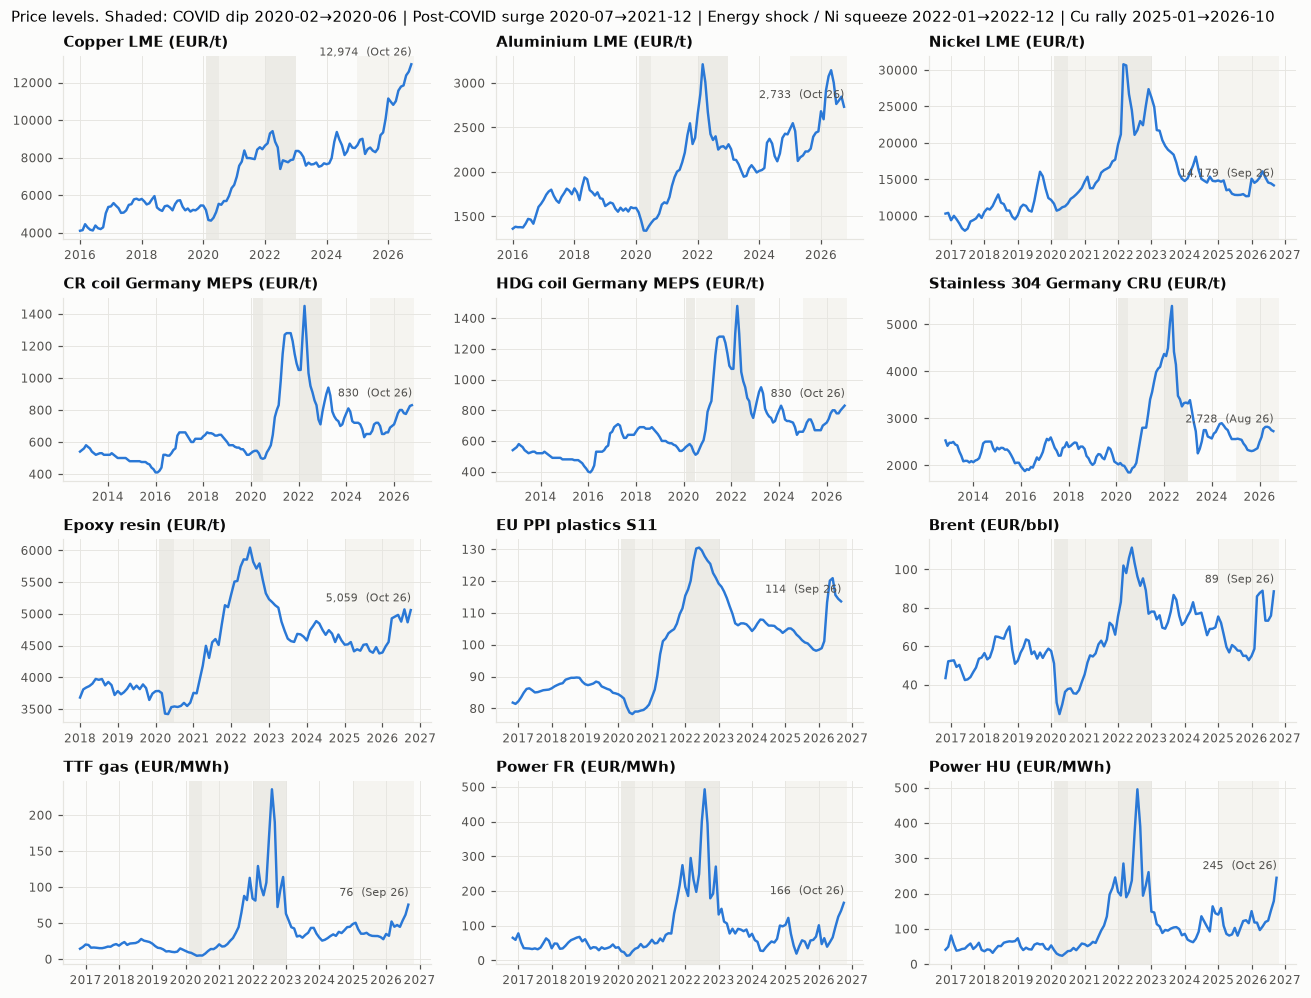

In [7]:
KEY = ["cu_eur", "al_eur", "ni_eur", "steel_cr_de", "steel_hdg_de", "ss304_de",
       "epoxy", "ppi_plastics", "brent_eur", "ttf_eur", "power_fr", "power_hu"]
pl.price_history(panel, KEY, REG, PLOTS);

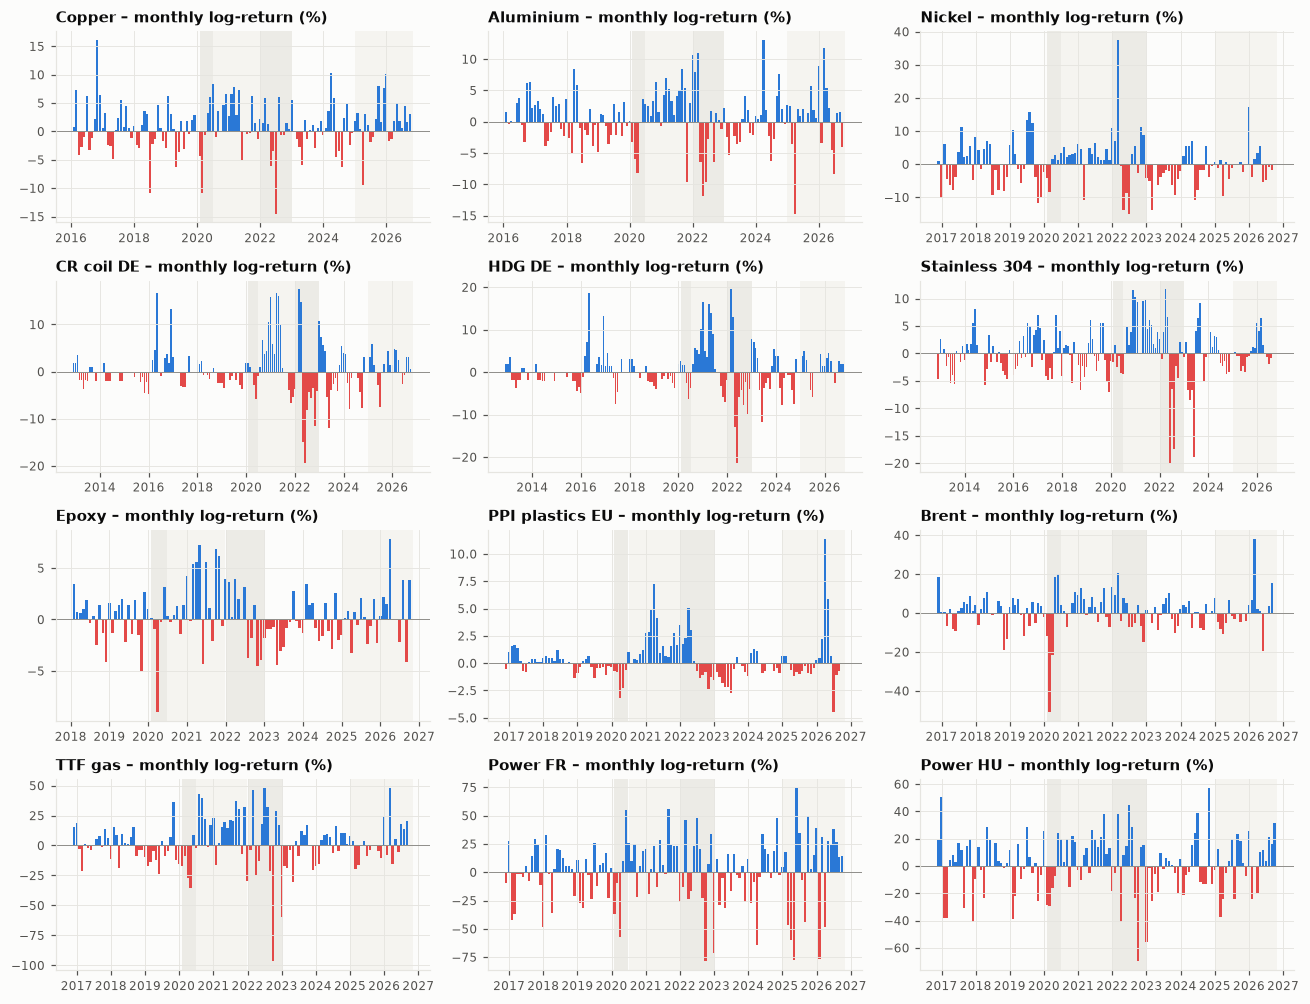

In [8]:
rets = eda.log_returns(panel)
pl.returns_grid(rets, KEY, REG, PLOTS);

In [9]:
ALL = [c for c in panel.columns if c != "eurusd"] + ["eurusd"]
summ = save(eda.return_summary(rets[ALL]), "return_summary")
display(summ.sort_values("vol_%/yr", ascending=False))

,n,mean_%/m,vol_%/m,vol_%/yr,skew,excess_kurt,JB_p,worst_m_%,best_m_%
Power FR,119.0,0.785,29.842,103.377,-0.557,0.293,3.744e-02,-78.803,74.380
Power DE,119.0,1.252,22.295,77.234,-0.580,1.803,1.123e-05,-81.457,67.037
Power HU,119.0,1.509,21.852,75.697,-0.386,0.447,1.392e-01,-69.983,57.121
TTF gas,118.0,1.408,20.467,70.900,-0.755,3.921,1.416e-19,-96.739,47.957
Benzene,105.0,0.397,19.853,68.773,-2.573,14.015,1.753e-212,-125.561,31.171
Brent,118.0,0.604,9.771,33.849,-0.811,6.973,1.923e-55,-50.943,38.190
Iron ore,118.0,0.203,9.032,31.289,-0.915,2.162,2.731e-09,-35.426,21.303
Nickel,118.0,0.270,7.156,24.790,1.148,5.054,1.257e-33,-14.883,37.432
HR coil DE,167.0,0.281,6.221,21.550,0.485,3.810,4.385e-24,-24.512,27.663
Zinc,118.0,0.326,5.699,19.743,-0.266,0.321,3.869e-01,-15.153,15.008


### H-month changes — first naive cost-at-risk
Overlapping windows: with ~120 months, H = 9 gives ~110 overlapping but only ~13 independent windows.

n_overlapping  n_independent   q05_%  q50_%   q95_%  P(rise>10%)
series          H                                                                  
Copper          3            127             42  -9.423  2.159  18.952        0.173
                6            124             20 -10.294  3.398  30.244        0.347
                9            121             13 -10.138  5.255  40.176        0.372
Aluminium       3            127             42 -11.041  1.502  17.679        0.173
                6            124             20 -13.668  2.495  28.684        0.331
                9            121             13 -14.746  1.885  37.917        0.372
CR coil DE      3            165             55 -14.802 -1.042  26.816        0.170
                6            162             27 -17.912 -2.523  51.349        0.210
                9            159             17 -19.865 -3.061  53.434        0.220
HDG DE          3            165             55 -14.560 -0.952  27.625        0.170
                6            162             27 -16.820 -2.041  48.104        0.204
                9            159             17 -19.302 -2.804  57.119        0.239
Stainless 304   3            163             54 -12.750 -0.625  18.443        0.178
                6            160             26 -19.552 -2.255  37.928        0.275
                9            157             17 -24.758 -3.902  51.614        0.287
Epoxy           3            102             34  -6.808  0.489  10.984        0.059
                6             99             16 -11.314  0.052  19.611        0.222
                9             96             10 -14.704 -1.202  28.268        0.240
PPI plastics EU 3            116             38  -5.209  0.047  11.583        0.069
                6            113             18  -8.211 -0.666  21.624        0.177
                9            110             12 -11.124 -0.660  27.631        0.227
Nickel          3            116             38 -18.382  0.362  22.444        0.302
                6            113             18 -25.754  2.751  34.189        0.372
                9            110             12 -27.799  2.315  47.568        0.427

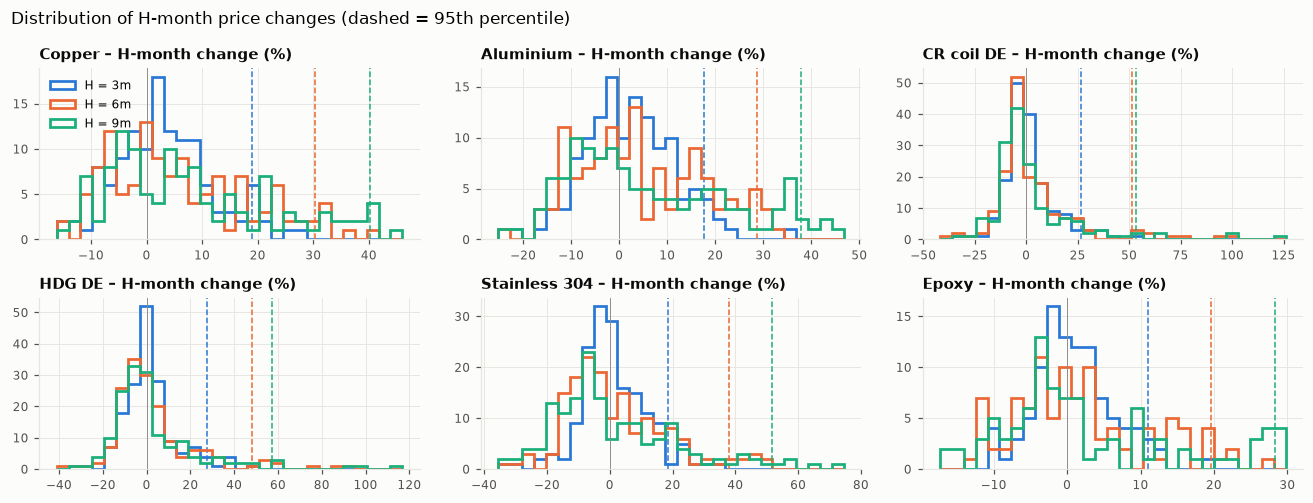

In [10]:
MAT = ["cu_eur", "al_eur", "steel_cr_de", "steel_hdg_de", "ss304_de", "epoxy"]
q = save(eda.h_change_quantiles(panel, MAT + ["ppi_plastics", "ni_eur"], H), "h_change_quantiles")
display(q)
pl.h_change_hist(panel, MAT, H, PLOTS);

### PPI vs market price
Is the Eurostat PPI calmer than the market price, and does it lag it?

,,n,vol_market_%/yr,vol_ppi_%/yr,ratio_ppi/market,corr_lag0,best_lead_m,corr_best,corr_levels
market,ppi,,,,,,,,
Copper,PPI Cu,118,14.595,9.636,0.660,0.933,0,0.933,0.992
Aluminium,PPI Al,118,16.270,5.636,0.346,0.424,1,0.634,0.912
CR coil DE,PPI steel DE,118,19.808,7.243,0.366,0.553,1,0.576,0.741
Stainless 304,PPI steel EU,117,17.978,7.468,0.415,0.539,0,0.539,0.826
HDG DE,PPI steel DE,118,19.516,7.243,0.371,0.573,0,0.573,0.731
CR coil DE,PPI steel EU,118,19.808,7.436,0.375,0.579,1,0.686,0.784


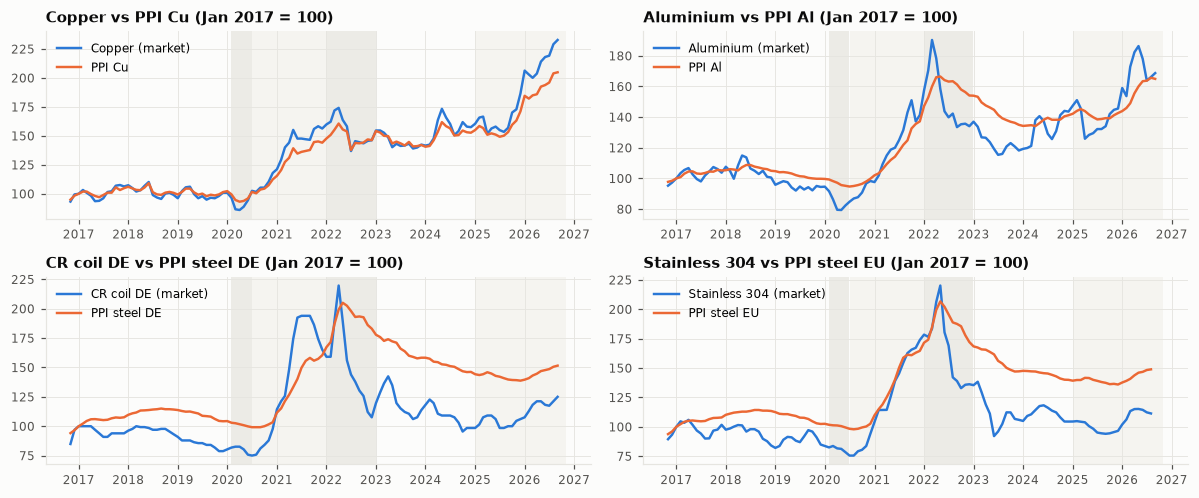

In [11]:
PAIRS = [("cu_eur", "ppi_cu"), ("al_eur", "ppi_al"), ("steel_cr_de", "ppi_steel_de"),
         ("ss304_de", "ppi_steel"), ("steel_hdg_de", "ppi_steel_de"), ("steel_cr_de", "ppi_steel")]
display(save(eda.vol_comparison(panel, PAIRS), "ppi_vs_market"))
pl.ppi_vs_market(panel, PAIRS[:4], REG, PLOTS);

### Volatility clustering

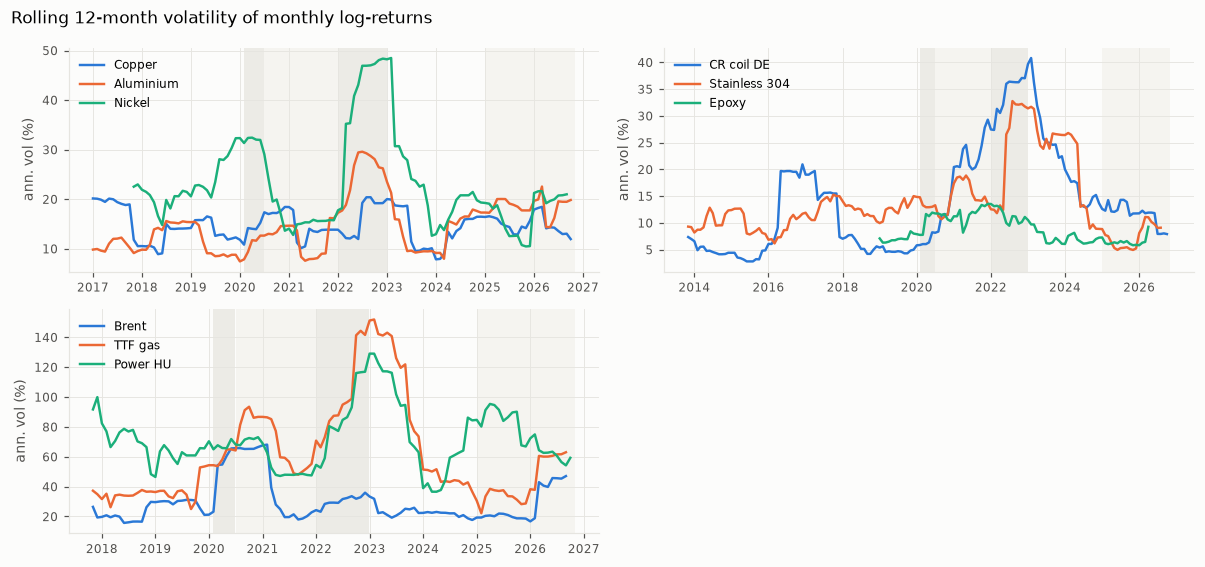

In [12]:
rv = eda.rolling_vol(rets)
pl.rolling_vol_plot(rv, ["cu_eur", "al_eur", "ni_eur", "steel_cr_de", "ss304_de", "epoxy",
                         "brent_eur", "ttf_eur", "power_hu"], REG, PLOTS);

,acf_r2_lag1,acf_r2_lag3,LB_p_r2_lag12,acf_r_lag1
Copper,0.004,-0.053,9.611e-01,0.203
Aluminium,0.128,0.105,1.090e-01,0.297
Nickel,-0.011,-0.011,7.015e-01,0.285
Zinc,0.200,0.122,6.648e-01,0.136
Iron ore,0.308,0.223,1.206e-02,0.223
CR coil DE,0.454,0.255,1.312e-15,0.535
CR coil FR,0.474,0.290,1.002e-16,0.538
HDG DE,0.314,0.325,5.556e-08,0.532
HR coil DE,0.255,0.310,8.381e-09,0.508
Stainless 304,0.147,0.074,4.522e-12,0.423


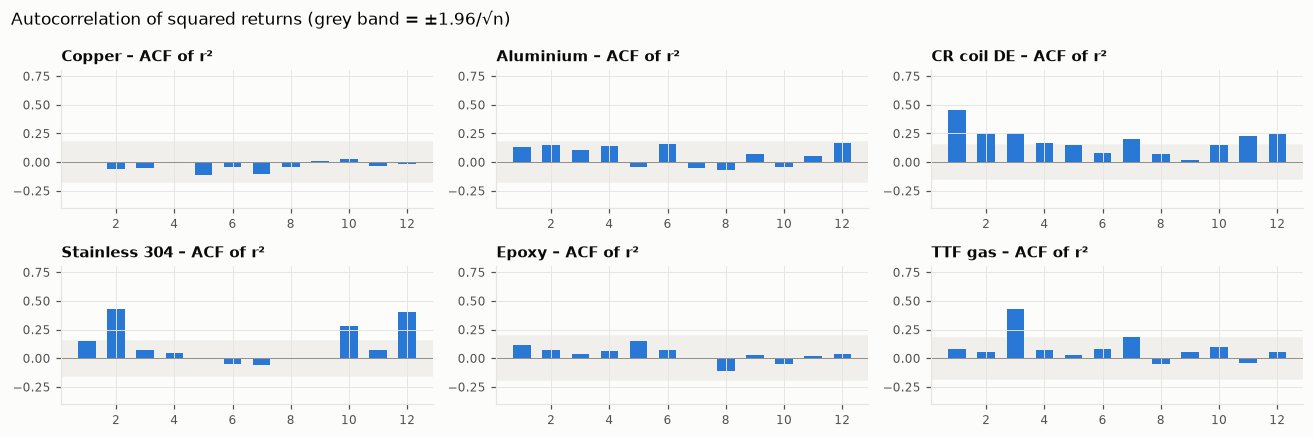

In [13]:
display(save(eda.arch_effects(rets[ALL]), "arch_effects"))
pl.acf_squared(rets, ["cu_eur", "al_eur", "steel_cr_de", "ss304_de", "epoxy", "ttf_eur"], PLOTS);

### Stationarity (ADF: H0 unit root; KPSS: H0 stationary)
Run on the common 2016-11 → 2026-09 window for comparability.

In [14]:
win = panel.loc["2016-11":"2026-09"]
display(save(eda.stationarity(win, ALL), "stationarity"))

,ADF_p_level,KPSS_p_level,ADF_p_return,KPSS_p_return,level_verdict,return_verdict
Copper,0.954,0.010,3.185e-02,0.1,non-stationary,stationary
Aluminium,0.583,0.010,1.033e-10,0.1,non-stationary,stationary
Nickel,0.304,0.010,2.371e-12,0.1,non-stationary,stationary
Zinc,0.374,0.100,7.079e-16,0.1,ambiguous,stationary
Iron ore,0.518,0.010,8.946e-11,0.1,non-stationary,stationary
CR coil DE,0.047,0.073,1.260e-01,0.1,stationary,check
CR coil FR,0.067,0.054,1.338e-05,0.1,ambiguous,stationary
HDG DE,0.050,0.090,1.340e-01,0.1,ambiguous,check
HR coil DE,0.358,0.068,3.523e-11,0.1,ambiguous,stationary
Stainless 304,0.267,0.090,3.264e-09,0.1,ambiguous,stationary


### Seasonality (calendar-month effect on returns)

In [15]:
SEAS = ["ppi_cu", "ppi_al", "ppi_steel", "ppi_plastics", "steel_cr_de", "cu_eur",
        "epoxy", "brent_eur", "ttf_eur", "power_fr", "power_hu", "power_de"]
display(save(eda.seasonality_test(rets[SEAS]), "seasonality"))

,F_p,KruskalWallis_p,max_month_mean_%,min_month_mean_%,peak_month,trough_month
PPI Cu,0.487,0.683,2.057,-1.109,1.0,7.0
PPI Al,0.844,0.774,1.149,-0.102,1.0,7.0
PPI steel EU,0.221,0.107,1.696,-0.557,4.0,11.0
PPI plastics EU,0.056,0.224,2.135,-0.896,4.0,7.0
CR coil DE,0.026,0.001,2.894,-3.018,3.0,6.0
Copper,0.570,0.699,2.688,-1.156,10.0,7.0
Epoxy,0.472,0.307,1.403,-1.327,10.0,9.0
Brent,0.971,0.813,4.387,-2.034,1.0,11.0
TTF gas,0.202,0.110,13.795,-8.497,8.0,4.0
Power FR,0.001,0.002,24.679,-26.214,6.0,4.0


## 3.2 Multivariate analysis

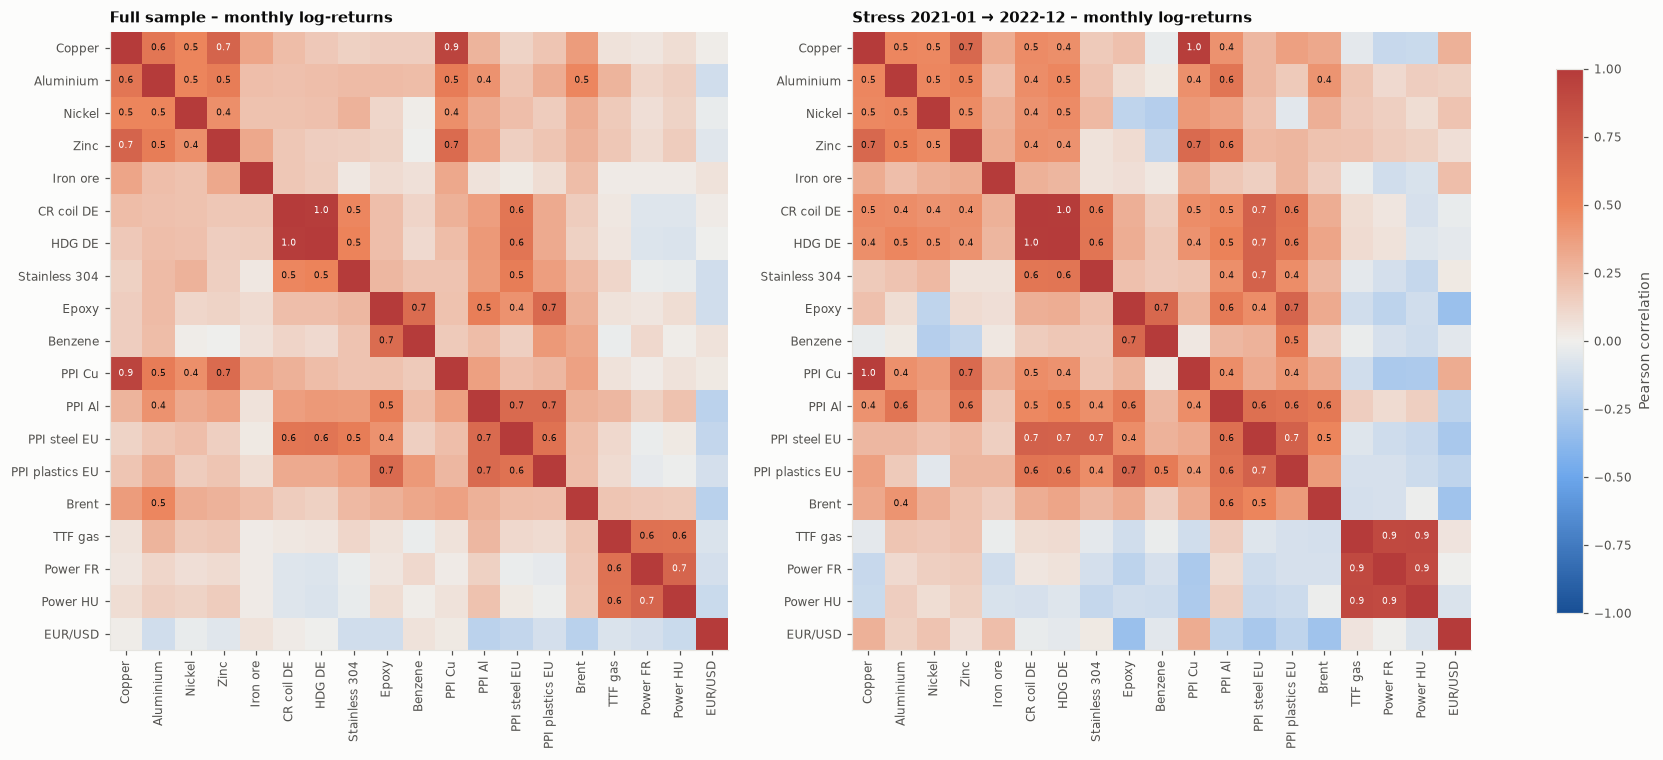

In [16]:
CORR = ["cu_eur", "al_eur", "ni_eur", "zn_eur", "iron_ore_eur", "steel_cr_de", "steel_hdg_de",
        "ss304_de", "epoxy", "benzene", "ppi_cu", "ppi_al", "ppi_steel", "ppi_plastics",
        "brent_eur", "ttf_eur", "power_fr", "power_hu", "eurusd"]
r_win = rets.loc["2016-12":"2026-09", CORR]
full = save(eda.correlation(r_win), "corr_full")
s0, s1 = cfg["stress_window"]
stress = save(eda.correlation(r_win, s0, s1), "corr_stress")
pl.corr_heatmaps(full, stress, PLOTS, f"{s0} → {s1}");

In [17]:
# Pairs whose correlation changes most in the stress window
diff = (stress - full).where(np.triu(np.ones(full.shape, bool), 1)).stack().dropna().sort_values()
display(pd.concat([diff.head(6), diff.tail(6)]).to_frame("stress − full"))

,,stress − full
PPI Cu,Power HU,-0.308
Brent,TTF gas,-0.296
Nickel,Epoxy,-0.294
PPI Cu,Power FR,-0.282
Brent,Power FR,-0.270
Nickel,Benzene,-0.232
TTF gas,Power FR,0.274
Zinc,HDG DE,0.276
PPI Cu,EUR/USD,0.278
CR coil DE,PPI plastics EU,0.279


### Lead–lag
corr(Δx at t−k, Δy at t). A significant k ≥ 1 means x is a usable leading indicator at forecast time
(before allowing for publication lags, handled in Step 4).

,corr_lag0,best_lead_m(k>=1),corr_at_best,approx_95%_band
Brent → PPI plastics EU,0.221,1,0.600,0.194
Brent → Epoxy,0.286,1,0.562,0.194
Benzene → Epoxy,0.652,6,0.100,0.194
TTF gas → PPI Al,0.255,1,0.369,0.194
TTF gas → PPI steel EU,0.102,6,0.285,0.194
Power DE → PPI steel EU,0.045,6,0.226,0.194
Nickel → Stainless 304,0.277,1,0.517,0.194
Iron ore → CR coil DE,0.183,1,0.373,0.194
Copper → PPI Cu,0.933,1,0.236,0.194
Aluminium → PPI Al,0.424,1,0.634,0.194


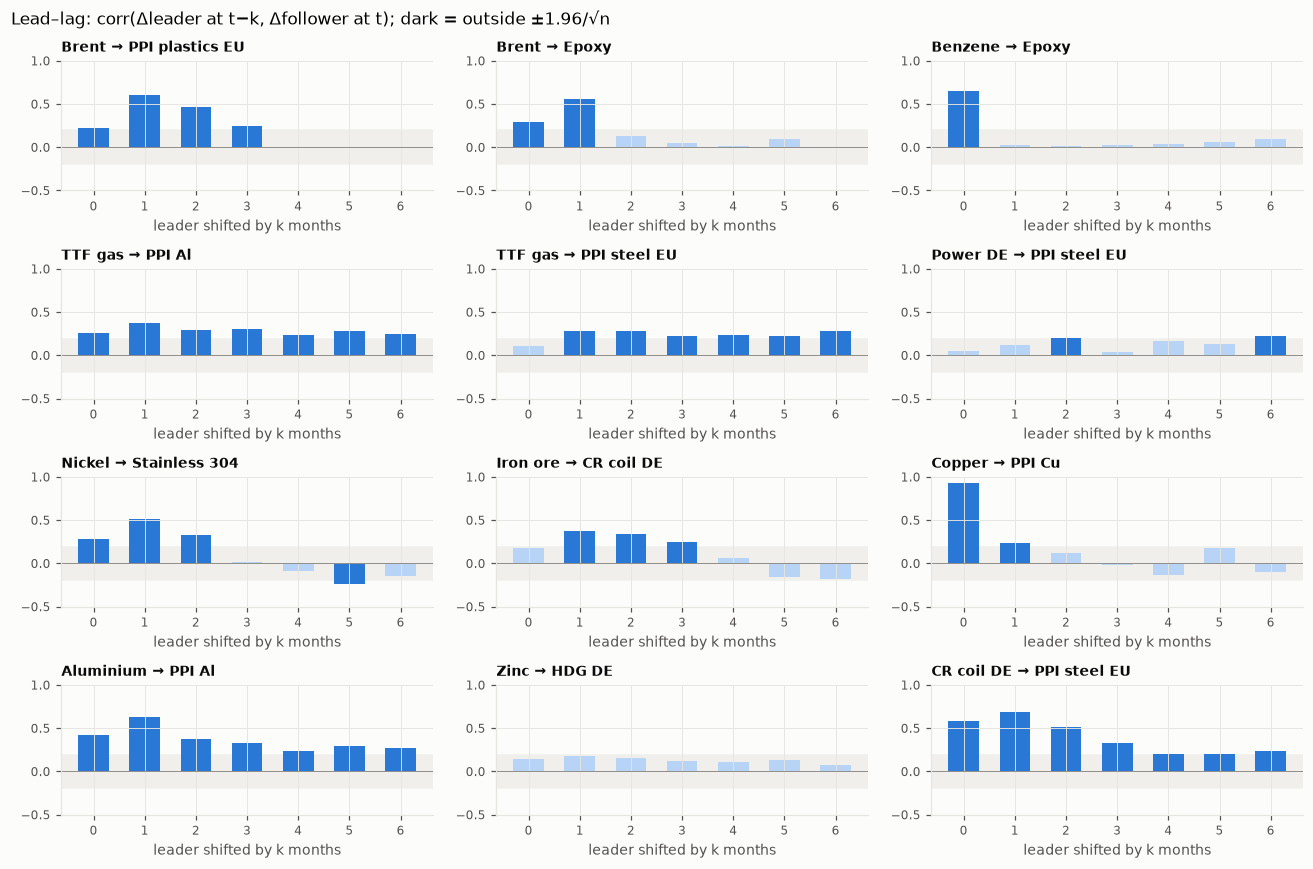

In [18]:
LL = [("brent_eur", "ppi_plastics"), ("brent_eur", "epoxy"), ("benzene", "epoxy"),
      ("ttf_eur", "ppi_al"), ("ttf_eur", "ppi_steel"), ("power_de", "ppi_steel"),
      ("ni_eur", "ss304_de"), ("iron_ore_eur", "steel_cr_de"), ("cu_eur", "ppi_cu"),
      ("al_eur", "ppi_al"), ("zn_eur", "steel_hdg_de"), ("steel_cr_de", "ppi_steel")]
ll1 = eda.lead_lag(win, LL, max_lag=6, change_window=1)
n = int(rets.loc["2016-12":"2026-09"].notna().sum().min())
display(save(eda.lead_lag_summary(ll1, n), "lead_lag_monthly"))
pl.lead_lag_plot(ll1, n, PLOTS);

In [19]:
# Same with 3-month changes (closer to a quarterly contract cycle; overlapping => band is optimistic)
ll3 = eda.lead_lag(win, LL, max_lag=6, change_window=3)
display(save(eda.lead_lag_summary(ll3, n // 3), "lead_lag_3m"))

,corr_lag0,best_lead_m(k>=1),corr_at_best,approx_95%_band
Brent → PPI plastics EU,0.470,1,0.694,0.336
Brent → Epoxy,0.548,1,0.700,0.336
Benzene → Epoxy,0.629,1,0.470,0.336
TTF gas → PPI Al,0.484,2,0.552,0.336
TTF gas → PPI steel EU,0.339,6,0.458,0.336
Power DE → PPI steel EU,0.227,6,0.405,0.336
Nickel → Stainless 304,0.492,1,0.629,0.336
Iron ore → CR coil DE,0.315,2,0.547,0.336
Copper → PPI Cu,0.965,1,0.767,0.336
Aluminium → PPI Al,0.571,1,0.725,0.336


## 3.3 Business-oriented EDA
Provisional cost formula (Step 2 placeholder, assumptions in `configs/eda.yaml`):
`UnitCost(t) = NonRM + Σ kg_i × Price_i(t) / 1000`. Polymers = assumed 2021 €/t level × S11/100.
NonRM sized so that unit cost in the reference month equals the RM6 teardown should-cost (€3,009) and an assumed €3,610 for AirSeT.

RM6: window 2016-11 → 2026-08; RM basket €784 = 26% of unit cost €3,009


,carbon_steel_unlabelled,stainless_304L,copper,galvanised_HDG,PET,aluminium
€ share of RM basket (%),14.2,19.4,61.3,2.2,1.1,1.8


RM_AirSeT: window 2016-11 → 2026-08; RM basket €639 = 18% of unit cost €3,610


,carbon_steel_CR,stainless_304L,PBT,ETP,aluminium
€ share of RM basket (%),41.0,43.8,6.9,6.1,2.2


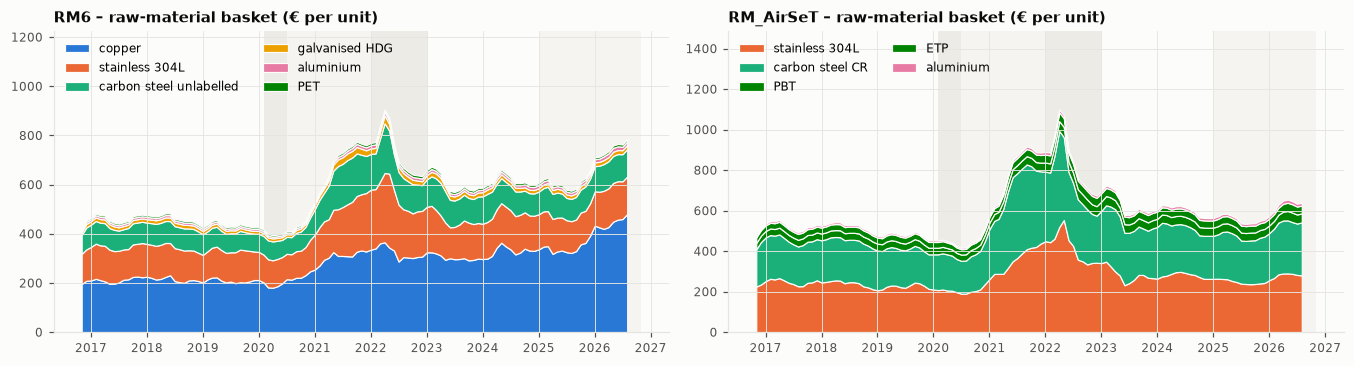

In [20]:
panel_c = cm.add_plastic_prices(panel, cfg["cost_model"]["plastic_levels_2021_eur_t"])
costs = {p: cm.unit_cost(panel_c, cfg, p) for p in cfg["cost_model"]["products"]}
ref = pd.Timestamp(cfg["cost_model"]["reference_month"])
for p, df in costs.items():
    row = df.loc[ref]
    mats = row.drop(["rm_cost", "non_rm", "unit_cost"])
    print(f"{p}: window {df.index[0]:%Y-%m} → {df.index[-1]:%Y-%m}; RM basket €{row.rm_cost:,.0f} "
          f"= {100*row.rm_cost/row.unit_cost:.0f}% of unit cost €{row.unit_cost:,.0f}")
    display((mats / row.rm_cost * 100).round(1).to_frame("€ share of RM basket (%)").T)
pl.cost_stack(costs, REG, PLOTS);

n   q05_%  q50_%   q95_%   max_%  P(rise)
product   series    H                                               
RM6       rm_cost   3  115.0  -8.730  0.896  18.141  25.602    0.548
                    6  112.0 -13.546  0.712  33.383  53.479    0.536
                    9  109.0 -14.311 -0.687  51.887  70.238    0.477
          unit_cost 3  115.0  -2.175  0.152   3.670   4.555    0.548
                    6  112.0  -3.182  0.131   6.165   9.087    0.536
                    9  109.0  -3.511 -0.147   8.628  11.080    0.477
RM_AirSeT rm_cost   3  115.0 -12.834 -0.044  23.349  33.982    0.496
                    6  112.0 -17.196 -1.096  44.429  66.421    0.446
                    9  109.0 -20.328 -3.878  62.175  93.716    0.376
          unit_cost 3  115.0  -2.478 -0.008   3.934   5.973    0.496
                    6  112.0  -3.479 -0.192   6.463   9.602    0.446
                    9  109.0  -4.477 -0.626   8.816  12.431    0.376

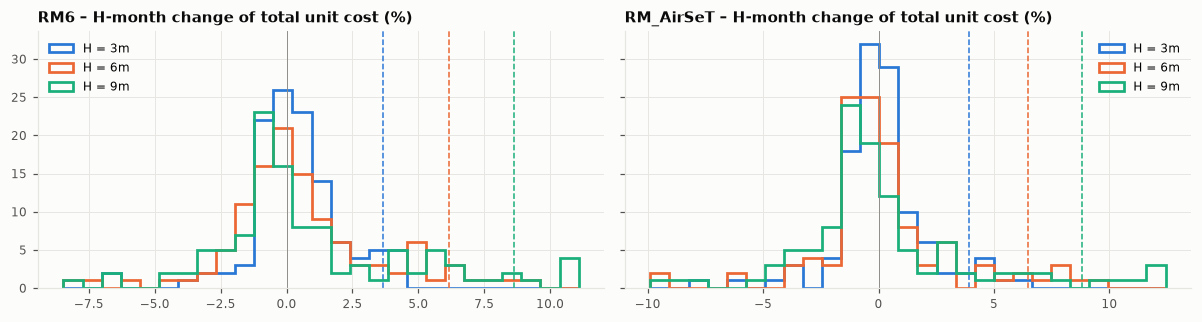

In [21]:
rows = []
for p, df in costs.items():
    for col in ["rm_cost", "unit_cost"]:
        t = eda.cost_h_changes(df, H, col)
        t.insert(0, "series", col); t.insert(0, "product", p)
        rows.append(t.reset_index())
display(save(pd.concat(rows).set_index(["product", "series", "H"]), "cost_h_changes"))
pl.cost_change_hist(costs, H, PLOTS);

### Risk decomposition — base BOM and alternative BOM scenarios

ETP  PBT  PET  aluminium  carbon_steel_CR  carbon_steel_unlabelled  copper  galvanised_HDG  stainless_304L
RM6       3  0.0  0.0  0.4        1.3              0.0                     25.6    36.0             3.9            32.8
          6  0.0  0.0  0.5        1.5              0.0                     25.0    35.4             3.8            33.8
          9  0.0  0.0  0.6        1.5              0.0                     24.7    34.9             3.8            34.5
RM_AirSeT 3  1.3  1.5  0.0        0.8             49.2                      0.0     0.0             0.0            47.3
          6  1.7  1.9  0.0        0.9             47.6                      0.0     0.0             0.0            47.8
          9  1.9  2.1  0.0        1.0             45.7                      0.0     0.0             0.0            49.3

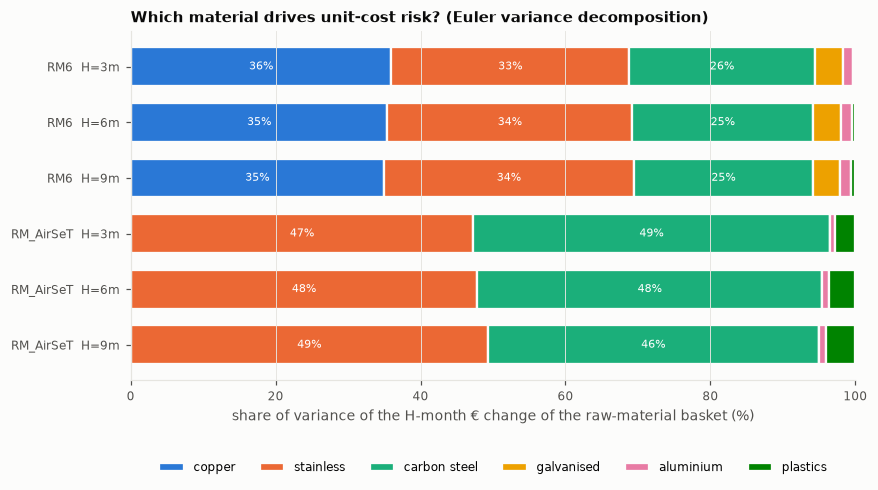

In [22]:
contrib = {}
for p in cfg["cost_model"]["products"]:
    mats = list(cm.product_materials(cfg, p))
    for h in H:
        contrib[(p, h)] = eda.risk_contribution(costs[p], mats, h)
contrib = save(pd.DataFrame(contrib).T.fillna(0), "risk_contribution")
display((100 * contrib).round(1))
pl.risk_contribution_plot(contrib, PLOTS);

In [23]:
# BOM scenarios: copper mass from the teardown (8.6 kg) for RM6; 'Other' 85.6 kg treated as epoxy for AirSeT
sc_rows = {}
for sc, spec in cfg["cost_model"]["scenarios"].items():
    df = cm.unit_cost(panel_c, cfg, spec["product"], sc)
    mats = list(cm.product_materials(cfg, spec["product"], sc))
    rc = eda.risk_contribution(df, mats, 6)
    ch = eda.cost_h_changes(df, [6], "unit_cost").loc[6]
    sc_rows[sc] = {**{f"share_{k}": 100 * v for k, v in rc.items()},
                   "RM basket €": df.loc[ref, "rm_cost"], "unit cost q95 6m %": ch["q95_%"]}
base6 = {p: eda.cost_h_changes(costs[p], [6], "unit_cost").loc[6, "q95_%"] for p in costs}
print("Base BOM, q95 of 6-month unit-cost change (%):", {k: round(v, 2) for k, v in base6.items()})
display(save(pd.DataFrame(sc_rows).T, "bom_scenarios"))

Base BOM, q95 of 6-month unit-cost change (%): {'RM6': np.float64(6.16), 'RM_AirSeT': np.float64(6.46)}


,share_carbon_steel_unlabelled,share_stainless_304L,share_copper,share_galvanised_HDG,share_PET,share_aluminium,RM basket €,unit cost q95 6m %,share_carbon_steel_CR,share_PBT,share_ETP,share_epoxy
RM6_teardown_copper,35.583,47.606,8.803,5.487,0.696,1.824,410.163,4.378,NaN,NaN,NaN,NaN
RM_AirSeT_other_as_epoxy,NaN,39.865,NaN,NaN,NaN,0.790,1072.614,8.909,36.776,1.856,1.628,19.085


### Historical "margin gamble"
At each past month t, price = cost_t / (1 − target margin), fixed for H months; material bought at delivery t+H
(worst case: no early purchase, no indexation, no hedge).

n_origins  mean_erosion_pts  p05_erosion_pts  worst_erosion_pts  P(margin < target)  P(erosion > 2 pts)  buffer_P90_%price  buffer_P95_%price
          H                                                                                                                                               
RM6       3      115.0            -0.221           -2.569             -3.189               0.548               0.096              1.868              2.569
          6      112.0            -0.418           -4.315             -6.361               0.536               0.179              3.292              4.315
          9      109.0            -0.620           -6.040             -7.756               0.477               0.239              4.544              6.040
RM_AirSeT 3      115.0            -0.081           -2.754             -4.181               0.496               0.087              1.519              2.754
          6      112.0            -0.151           -4.524             -6.722               0.446               0.134              3.201              4.524
          9      109.0            -0.206           -6.171             -8.702               0.376               0.183              3.907              6.171

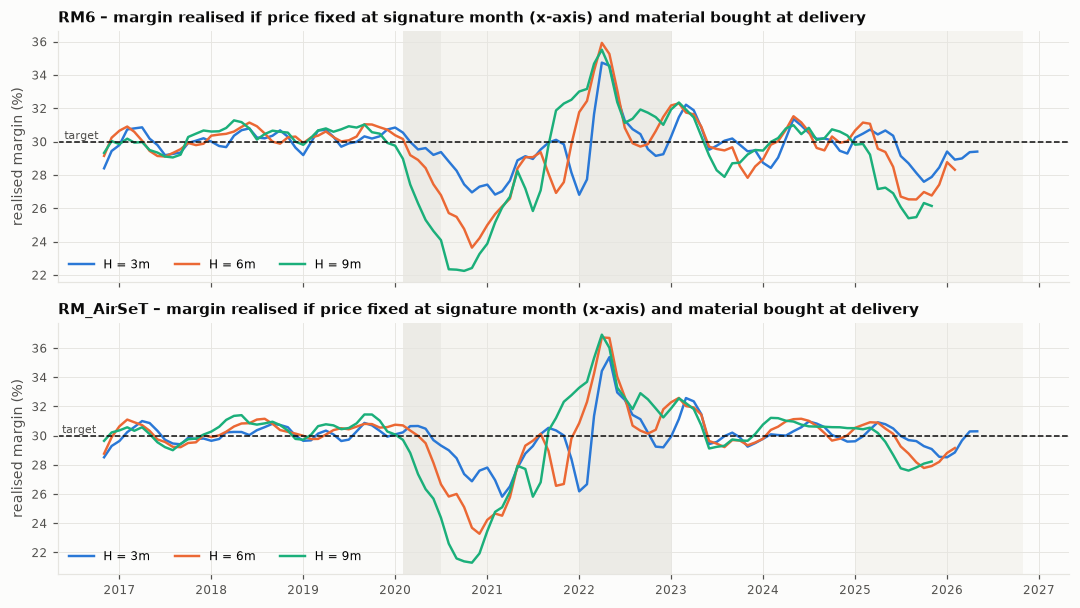

In [24]:
m, tol = cfg["cost_model"]["target_margin"], cfg["cost_model"]["breach_tolerance_pts"]
gambles = {p: {h: eda.margin_gamble(costs[p], h, m) for h in H} for p in costs}
summ_g = pd.concat({p: eda.margin_gamble_summary(costs[p], H, m, tol) for p in costs})
display(save(summ_g, "margin_gamble_summary"))
pl.margin_gamble_plot(gambles, m, REG, PLOTS);

In [25]:
# Worst signature months per product at H = 9
for p in costs:
    g = gambles[p][9]
    print(p); display((100 * g["erosion_pts"]).nsmallest(5).to_frame("erosion (margin pts)"))

RM6


,erosion (margin pts)
month,
2020-10-01,-7.756
2020-09-01,-7.682
2020-08-01,-7.660
2020-11-01,-7.583
2020-12-01,-6.740


RM_AirSeT


,erosion (margin pts)
month,
2020-11-01,-8.702
2020-10-01,-8.612
2020-09-01,-8.413
2020-12-01,-8.068
2020-08-01,-7.398


### Extra: does the selling price follow raw-material cost?
Synthetic yearly benchmark P50 vs the RM6 cost model, and SF6 brands vs the SF6-free Eaton Xiria (dotted line = 2026
EU F-gas SF6 ban for new ≤24 kV switchgear).

,ABB,Eaton,Ormazabal,Schneider Electric,Siemens,SwitchGear Company,RM6 RM basket,RM6 unit cost
Year,,,,,,,,
2017,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2018,100.4,101.4,99.6,100.9,100.0,100.4,100.1,100.0
2019,101.8,97.2,100.9,101.2,100.4,100.0,93.9,99.0
2020,100.6,98.6,99.5,100.4,100.4,99.7,91.2,98.5
2021,107.8,104.9,110.6,107.2,108.9,106.5,149.1,108.5
2022,114.3,106.9,116.4,115.0,116.6,113.2,159.2,110.2
2023,121.8,108.3,121.6,116.3,121.9,121.1,131.5,105.4
2024,122.5,108.3,124.3,120.7,122.1,123.9,132.9,105.7
2025,122.3,107.2,124.5,120.9,122.1,126.1,131.1,105.4


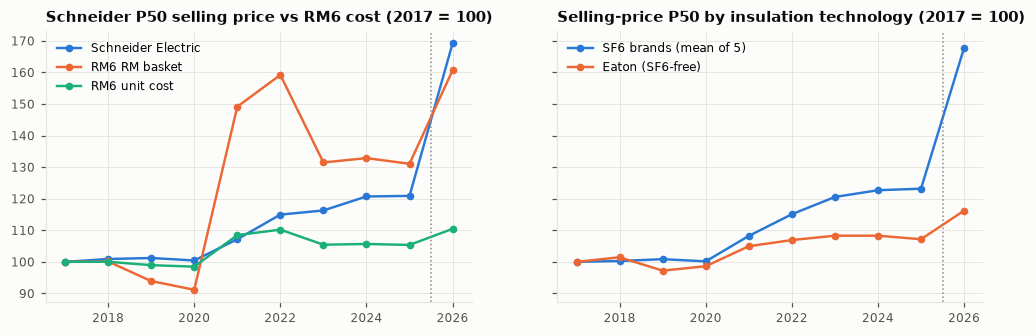

In [26]:
idx = save(eda.price_vs_cost(bench, costs["RM6"]), "price_vs_cost_index")
display(idx.round(1))
pl.price_vs_cost_plot(idx, PLOTS);

In [27]:
# Year-on-year correlation between Schneider's P50 price change and RM6 cost change (only 9 points!)
yoy = idx.pct_change().dropna()
print("corr(ΔP50 SE, ΔRM basket) =", round(yoy["Schneider Electric"].corr(yoy["RM6 RM basket"]), 2))
print("corr(ΔP50 SE, ΔRM basket) excl. 2026 =",
      round(yoy.drop(2026)["Schneider Electric"].corr(yoy.drop(2026)["RM6 RM basket"]), 2))

corr(ΔP50 SE, ΔRM basket) = 0.38
corr(ΔP50 SE, ΔRM basket) excl. 2026 = 0.66
